# Lab 2.3 Classification (with neurons)

> **From the slide to the code** — slide *BERT*
> - "BERT (Google, 2018): a Transformer encoder pre-trained on lots of text. It reads the sentence in both directions, so the same word gets a different vector in each context (unlike Word2Vec)"
> - "bert-base: 12 layers, 768-dim vectors, 30,522 sub-words" → `BertConfig` below: `num_hidden_layers`, `hidden_size`, `vocab_size`

BERT (Bidirectional Encoder Representations from Transformers) is a language representation model developed by Google in 2018. It is pre-trained on a large amount of text, and then it can be adapted (**fine-tuned**) to a specific task, such as classifying reviews.

> **Use a GPU** in Colab (*Runtime → Change runtime type → GPU*): the fine-tuning sections below are very slow on CPU.

In [1]:
from transformers import BertTokenizer, BertModel, BertConfig

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# this will download the BERT Tokenizer
bert_tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")
# this will download the BERT Trained Model
bert_model = BertModel.from_pretrained('bert-base-uncased')

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


You could also use the config class to initialize the network. Mainly when you don't want to use a pretrained model, but only a standard set of hyper parameters.

In [3]:
config = BertConfig.from_pretrained("bert-base-uncased")
# bert_model = BertModel.from_config(config)
config

BertConfig {
  "add_cross_attention": false,
  "architectures": [
    "BertForMaskedLM"
  ],
  "attention_probs_dropout_prob": 0.1,
  "bos_token_id": null,
  "classifier_dropout": null,
  "eos_token_id": null,
  "gradient_checkpointing": false,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "is_decoder": false,
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "bert",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "pad_token_id": 0,
  "position_embedding_type": "absolute",
  "tie_word_embeddings": true,
  "transformers_version": "5.22.2",
  "type_vocab_size": 2,
  "use_cache": true,
  "vocab_size": 30522
}

In [4]:
# split a sentence into BERT tokens
sentence = 'Just an example, random words: pytorch vs tensorflow'
tokens = bert_tokenizer.tokenize(sentence)
print(tokens)

['just', 'an', 'example', ',', 'random', 'words', ':', 'p', '##yt', '##or', '##ch', 'vs', 'tensor', '##flow']


BERT tokens are neither words, nor characters, nor lemmas or stems: they are **sub-words** (WordPiece). Frequent words stay whole (`just`, `example`), rare words are split into pieces: `pytorch` → `p`, `##yt`, `##or`, `##ch` (`##` = this piece continues the previous one).

## Sentence tokenizer encoding and decoding

> **From the slide to the code** — slide *BERT*
> - "[CLS] at the start, [SEP] at the end, [PAD] up to max_length" → `bert_tokenizer(sentence, add_special_tokens=True, max_length=30, padding='max_length')` (in the slide: `encode_plus`, the old name)
> - "attention_mask = 1 for real tokens, 0 for padding" → `return_attention_mask=True`; back to text: `decode`

To pass the sentences to the model we turn them into integers (calling the tokenizer on the sentence), and to read the output we turn the integers back into tokens (`decode`).

In [5]:
# encode the sentence: ids of the tokens, + [CLS] and [SEP], padded with [PAD] up to 30 positions
ids_encode = bert_tokenizer(          # (old versions: bert_tokenizer.encode_plus, removed in transformers 5)
    sentence,
    add_special_tokens = True,
    max_length = 30,
    return_attention_mask = True,
    padding="max_length",
    truncation=True
)
print("encode:",ids_encode)

encode: {'input_ids': [101, 2074, 2019, 2742, 1010, 6721, 2616, 1024, 1052, 22123, 2953, 2818, 5443, 23435, 12314, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]}


In [6]:
# back from ids to text
print("decode:", bert_tokenizer.decode(ids_encode['input_ids']))

decode: [CLS] just an example, random words : pytorch vs tensorflow [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]


In [7]:
bert_tokenizer.convert_ids_to_tokens(101) # the token of id 101: a special token

'[CLS]'

# Exercise 3.1: special tokens, padding and truncation

Use `sentence` and the output of the cells above.

1. The sentence has 14 tokens: why does `input_ids` start with 16 values different from 0? Which ids are `[CLS]`, `[SEP]` and `[PAD]`?
2. What is the `attention_mask` for, and why does it end with 0s?
3. Encode the same sentence with `max_length=10`. Which tokens are lost? Is `[SEP]` still there?

*Hint: `bert_tokenizer.convert_ids_to_tokens(list_of_ids)` turns a list of ids into tokens.*

In [21]:
# Your code here

We can use BERT to compare the meaning of sentences: one vector per sentence, then the cosine similarity (as in Lab 1).

In [11]:
import torch
import torch.nn.functional as F

# Define input texts
text1 = "I enjoy walking in the park."
text2 = "I love going for a stroll in the garden."
text3 = "I dislike being stuck in traffic."

# one vector per sentence: the vector of the [CLS] token (position 0) in the last layer
def get_embedding(text, tokenizer, model):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=512)
    with torch.no_grad():                                   # no training: no gradients needed
        outputs = model(**inputs)
    cls_embedding = outputs.last_hidden_state[:, 0, :]  # Shape: (batch_size, hidden_dim)
    return cls_embedding

# Get embeddings for the texts
embedding1 = get_embedding(text1, bert_tokenizer, bert_model)
embedding2 = get_embedding(text2, bert_tokenizer, bert_model)
embedding3 = get_embedding(text3, bert_tokenizer, bert_model)

# Compute cosine similarities
similarity_1_2 = F.cosine_similarity(embedding1, embedding2).item()
similarity_1_3 = F.cosine_similarity(embedding1, embedding3).item()
similarity_2_3 = F.cosine_similarity(embedding2, embedding3).item()

# Print results
print(f"Similarity between Text1 and Text2: {similarity_1_2:.4f}")
print(f"Similarity between Text1 and Text3: {similarity_1_3:.4f}")
print(f"Similarity between Text2 and Text3: {similarity_2_3:.4f}")

Similarity between Text1 and Text2: 0.9593
Similarity between Text1 and Text3: 0.9355
Similarity between Text2 and Text3: 0.9364


**Careful:** the three similarities are all very high, even for the sentence about traffic. The `[CLS]` vector of a BERT that was **not fine-tuned** is not a good sentence embedding: it was trained for next-sentence prediction, not for similarity.

A common alternative is **mean pooling**: the average of the vectors of all tokens (padding excluded). Compare the numbers! (Models trained for similarity, like Sentence-BERT, do even better.)

In [12]:
def get_mean_embedding(text, tokenizer, model):
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=512)
    with torch.no_grad():
        outputs = model(**inputs)
    mask = inputs["attention_mask"].unsqueeze(-1)            # 1 = real token, 0 = padding
    summed = (outputs.last_hidden_state * mask).sum(dim=1)
    return summed / mask.sum(dim=1)                          # average over the real tokens

mean1, mean2, mean3 = (get_mean_embedding(t, bert_tokenizer, bert_model) for t in (text1, text2, text3))

print(f"Mean pooling - Text1 vs Text2: {F.cosine_similarity(mean1, mean2).item():.4f}")
print(f"Mean pooling - Text1 vs Text3: {F.cosine_similarity(mean1, mean3).item():.4f}")
print(f"Mean pooling - Text2 vs Text3: {F.cosine_similarity(mean2, mean3).item():.4f}")

Mean pooling - Text1 vs Text2: 0.8909
Mean pooling - Text1 vs Text3: 0.7481
Mean pooling - Text2 vs Text3: 0.6723


# Fine-tuning

> **From the slide to the code** — slide *Fine-tuning & PEFT*
> - "Fine-tuning: keep training a pre-trained model on a small dataset (1,000 Yelp reviews, 5 classes = stars)" → `AutoModelForSequenceClassification.from_pretrained(..., num_labels=5)`
> - "PEFT: train only a few of BERT's 108M parameters": full 108,314,117 (100%) · head only 3,845 (0.0035%) · LoRA r = 16: 593,669 (0.55%) → `print_trainable_parameters(model)`


Fine-tuning is a machine learning process where a pre-trained model is adapted to a specific task or domain by further training it on a smaller, task-specific dataset. This approach leverages the knowledge the model has already learned during its initial training on a large and general-purpose dataset, making it a powerful method for solving specialized problems efficiently.

### Why Fine-Tuning is Important
- **Efficient Use of Resources:** Training a model from scratch requires massive datasets and extensive computational power. Fine-tuning eliminates the need for this by building upon a pre-trained model.

- **Domain Adaptation:** Pre-trained models may not perform optimally in niche areas (e.g., medical imaging or legal documents). Fine-tuning allows the model to specialize in these domains.

- **Improved Performance:** Fine-tuning aligns the pre-trained model's features with task-specific requirements, often leading to state-of-the-art results.

- **Transfer Learning:** Fine-tuning is a key component of transfer learning, enabling the use of a general-purpose model in a new, related task.

We compare four ways to fine-tune the same BERT on the same reviews: **all** the parameters, only the **head** (the final classifier), **LoRA** and **AdaLoRA**. Fewer trainable parameters = faster and lighter training, but maybe lower accuracy: how much do we lose?

To get some extra speed, select a GPU. Be aware that there are usage limits, so use it strategically.

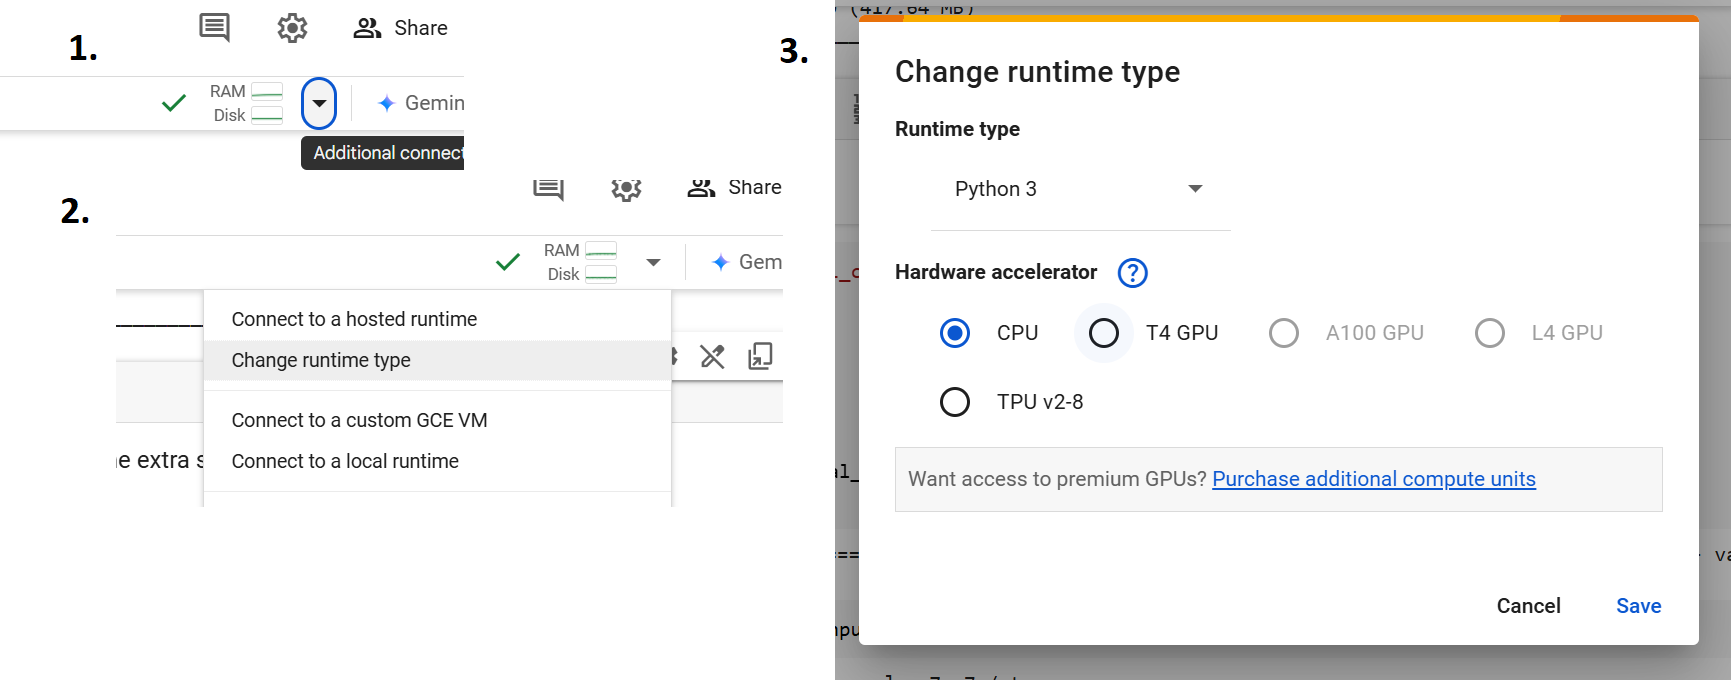


## PEFT

PEFT (Parameter-Efficient Fine-Tuning) trains only a small part of the parameters. **LoRA** freezes each weight matrix W and learns a small update **B·A**, where B and A have a low rank r (here r = 16): instead of a 768 × 768 matrix, two thin ones of 768 × r and r × 768. **AdaLoRA** starts from the same idea, but moves the rank to the layers where it is most useful.

We use the Hugging Face libraries: `transformers` (models), `datasets` (data), `peft` (LoRA, AdaLoRA), `evaluate` (metrics), on top of PyTorch.

In [10]:
!pip install peft datasets evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.9 MB/s eta 0:00:00


In [14]:
import math
import numpy as np
import torch

import evaluate
from datasets import load_dataset
from peft import LoraConfig, AdaLoraConfig, get_peft_model
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, TrainerCallback)

In [15]:
model_name_or_path = "google-bert/bert-base-cased"
tokenizer_name_or_path = "google-bert/bert-base-cased"

In [16]:
dataset = load_dataset('Yelp/yelp_review_full')   # Yelp reviews, label 0-4 = 1-5 stars (recent versions want 'owner/name')

print(dataset)
print(dataset["train"][100])

tokenizer = AutoTokenizer.from_pretrained(tokenizer_name_or_path)

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        padding='max_length',
        truncation=True
        )

# First select 1000 + 1000 reviews, then tokenize only those
# (tokenizing all 650,000 reviews and then keeping 1000 takes a long time and a lot of RAM)
small_train_dataset = dataset["train"].shuffle(seed=42).select(range(1000)).map(tokenize_function, batched=True)
small_eval_dataset = dataset["test"].shuffle(seed=42).select(range(1000)).map(tokenize_function, batched=True)

DatasetDict({
    train: Dataset({
        features: ['label', 'text'],
        num_rows: 650000
    })
    test: Dataset({
        features: ['label', 'text'],
        num_rows: 50000
    })
})
{'label': 0, 'text': 'My expectations for McDonalds are t rarely high. But for one to still fail so spectacularly...that takes something special!\\nThe cashier took my friends\'s order, then promptly ignored me. I had to force myself in front of a cashier who opened his register to wait on the person BEHIND me. I waited over five minutes for a gigantic order that included precisely one kid\'s meal. After watching two people who ordered after me be handed their food, I asked where mine was. The manager started yelling at the cashiers for \\"serving off their orders\\" when they didn\'t have their food. But neither cashier was anywhere near those controls, and the manager was the one serving food to customers and clearing the boards.\\nThe manager was rude when giving me my order. She didn\'t mak

## Define Training and Evaluation Loop

We also introduce an auxiliary function to count the number of trainable parameters in each case.



In [18]:
def train_and_evaluate(model, max_steps=-1, num_train_epochs=2, learning_rate=5e-5, callbacks=None):
    metric = evaluate.load("accuracy")

    def compute_metrics(eval_pred):
        logits, labels = eval_pred
        predictions = np.argmax(logits, axis=-1)
        return metric.compute(predictions=predictions, references=labels)

    training_args = TrainingArguments(
        report_to=[],
        output_dir="test_trainer",
        num_train_epochs=num_train_epochs,
        max_steps=max_steps,
        learning_rate=learning_rate,
        label_names=["labels"],
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=small_train_dataset,
        eval_dataset=small_eval_dataset,
        compute_metrics=compute_metrics,
        callbacks=callbacks,
    )

    train_metrics = trainer.train()
    print(train_metrics)
    eval_metrics = trainer.evaluate()
    eval_metrics["train_runtime"] = train_metrics.metrics["train_runtime"]   # seconds spent training
    print(eval_metrics)
    return eval_metrics

results = {}  # eval metrics of each fine-tuning method, compared at the end

def print_trainable_parameters(model):
    """
    Prints the number of trainable parameters in the model.
    """
    trainable_params = 0
    all_param = 0
    for _, param in model.named_parameters():
        all_param += param.numel()
        if param.requires_grad:
            trainable_params += param.numel()
    print(
        f"trainable params: {trainable_params} || all params: {all_param} || trainable: {100 * trainable_params / all_param:.4f}%"
    )

## Full fine-tuning

In [19]:
# BERT + a new classifier with 5 outputs (one per star); all the parameters are trainable
model = AutoModelForSequenceClassification.from_pretrained(model_name_or_path, num_labels=5)
print_trainable_parameters(model)

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 108314117 || all params: 108314117 || trainable: 100.0000%


In [ ]:
results["full"] = train_and_evaluate(model, learning_rate=5e-5)

## Head fine-tuning

# Exercise 3.2: how many parameters do we train?

No training needed: only `print_trainable_parameters`.

1. **Head only:** load a new `AutoModelForSequenceClassification` and make trainable only the parameters of the final classifier (their names start with `classifier.`). How many trainable parameters? What share of the whole model?
2. **LoRA:** `get_peft_model(model, LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, bias="none", task_type="SEQ_CLS"))` leaves 593,669 trainable parameters (see *LoRA fine-tuning* below). How many with `r = 4`, `8`, `32`? How does the number grow with r?

*Hint: `for name, param in model.named_parameters(): param.requires_grad = ...` (True = trainable).*

In [21]:
# Your code here

In [24]:
# train only the head (the model of the solution above, or your own)
results["head"] = train_and_evaluate(model, learning_rate=5e-5)

/usr/local/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss


TrainOutput(global_step=80, training_loss=1.6252649307250977, metrics={'train_runtime': 437.4324, 'train_samples_per_second': 1.463, 'train_steps_per_second': 0.183, 'total_flos': 168395611176960.0, 'train_loss': 1.6252649307250977, 'epoch': 2.0})


/usr/local/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Step,Accuracy
No log,1.675921,80,0.250000


{'eval_loss': 1.6759209632873535, 'eval_accuracy': 0.25, 'train_runtime': 437.4324}


## LoRA fine-tuning

In [25]:
model = AutoModelForSequenceClassification.from_pretrained(model_name_or_path, num_labels=5)
# LoRA: rank r = 16; lora_alpha scales the update B·A; task_type="SEQ_CLS" also keeps the classifier trainable
peft_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="SEQ_CLS",
)
model = get_peft_model(model, peft_config)
print_trainable_parameters(model)

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 593669 || all params: 108907786 || trainable: 0.5451%


In [ ]:
results["lora"] = train_and_evaluate(model, learning_rate=5e-5)

## AdaLoRA fine-tuning

> **From the slide to the code** — slide *Fine-tuning & PEFT*
> - "AdaLoRA: the rank adapts per layer (call `update_and_allocate` at every step)" → `AdaLoraUpdateCallback` below

In [27]:
model = AutoModelForSequenceClassification.from_pretrained(model_name_or_path, num_labels=5)

# AdaLoRA must know how many training steps there are.
# Trainer default batch size = 8: 1000 reviews / 8 = 125 steps per epoch, x 2 epochs = 250 steps
total_steps = math.ceil(len(small_train_dataset) / 8) * 2

peft_config = AdaLoraConfig(
    init_r=16,          # starting rank of every layer
    target_r=8,         # average rank at the end: AdaLoRA moves rank to the important layers
    lora_alpha=16,
    task_type="SEQ_CLS",
    lora_dropout=0.01,
    total_step=total_steps,
    tinit=25,           # first steps: no rank changes (warm-up)
    tfinal=50,          # last steps: ranks are fixed
)
model = get_peft_model(model, peft_config)
print_trainable_parameters(model)

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 594053 || all params: 108908194 || trainable: 0.5455%


In [ ]:
class AdaLoraUpdateCallback(TrainerCallback):
    """Trainer does not update AdaLoRA's ranks by itself:
    we call update_and_allocate after every optimizer step (gradients are still there)."""
    def __init__(self, peft_model):
        self.peft_model = peft_model

    def on_optimizer_step(self, args, state, control, **kwargs):
        self.peft_model.base_model.update_and_allocate(state.global_step)

results["adalora"] = train_and_evaluate(model, learning_rate=5e-5,
                                        callbacks=[AdaLoraUpdateCallback(model)])

## Comparison

Same data, same number of epochs, same learning rate: how much accuracy do we lose by training fewer parameters?

> **Try it (with a GPU):** the learning rate 5e-5 is good for full fine-tuning, but small for the head only and for LoRA, which usually use 1e-4 … 1e-3. Train them again with a higher learning rate and compare.

In [ ]:
import pandas as pd

# one row per method: accuracy and loss on the 1,000 test reviews, training time (seconds)
pd.DataFrame(results).T[["eval_accuracy", "eval_loss", "train_runtime"]]

## ✨ Resources used for this tutorial and references
- [LORA: Low-Rank Adaptation of Large Language Models](https://arxiv.org/pdf/2106.09685)
- [DoRA: Weight-Decomposed Low-Rank Adaptation](https://arxiv.org/pdf/2402.09353)
- [AdaLoRA: Adaptive Budget Allocation for Parameter-Efficient Fine-Tuning](https://arxiv.org/pdf/2303.10512)
- [HuggingFace PEFT Tutorial](https://huggingface.co/blog/peft)
- [HuggingFace PEFT Tutorial for image classification](https://huggingface.co/docs/peft/main/en/task_guides/image_classification_lora)
- [HuggingFace Training Tutorial](https://huggingface.co/docs/transformers/training)